In [9]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

df = pd.read_csv("dataset.csv")


In [10]:
features = [
    "danceability",
    "energy",
    "valence",
    "acousticness",
    "speechiness",
    "instrumentalness",
    "tempo"
]

# Keep a random sample of songs with complete feature values
sample = df.dropna(subset=features).sample(
    n=10000, random_state=42
).copy()


scaler = StandardScaler()
X = scaler.fit_transform(sample[features])

In [11]:
# Test different values of k
for k in range(2, 11):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    labels = model.fit_predict(X)

    inertia = model.inertia_
    silhouette = silhouette_score(
        X, labels, sample_size=2000,
        random_state=42
    )

    print(
        f"k={k}, inertia={inertia:.2f}, "
        f"silhouette={silhouette:.3f}"
    )

k=2, inertia=54849.98, silhouette=0.259
k=3, inertia=46912.13, silhouette=0.206
k=4, inertia=41385.05, silhouette=0.215
k=5, inertia=36951.78, silhouette=0.216
k=6, inertia=32991.30, silhouette=0.233
k=7, inertia=30320.83, silhouette=0.217
k=8, inertia=28637.90, silhouette=0.205
k=9, inertia=26678.00, silhouette=0.211
k=10, inertia=25427.94, silhouette=0.200


In [12]:
# Create the K-means model with 6 clusters
kmeans = KMeans(
    n_clusters=6,
    random_state=42,
    n_init=10
)

sample["cluster"] = kmeans.fit_predict(X)

print(sample[["track_name", "artists", "cluster"]].head(20))

                                               track_name  \
113186                                      No Other Name   
42819                                      Failed Organum   
59311                               Save the Trees, Pt. 1   
91368                                     Merry Christmas   
61000                                               月の大きさ   
96815                              Jah Jah Revolta, Pt. 2   
18939                           Please Stop Communicating   
72760                                   A Form of Protest   
25788                              I'm Ready - Radio Edit   
87169                 Proibida Pra Mim (Grazon) - Ao Vivo   
19261   I'll Be Home For Christmas - From The Kacey Mu...   
62735                                               時間がない   
108051                                                Sur   
77161   Pega pega (Participação especial de Jojo Maron...   
115                               In Case You Didn’t Know   
87994                   

In [13]:
# Calculate average audio features for each cluster
cluster_profiles = sample.groupby("cluster")[features].mean()

print(cluster_profiles.round(3))

         danceability  energy  valence  acousticness  speechiness  \
cluster                                                             
0               0.697   0.724    0.697         0.213        0.078   
1               0.507   0.374    0.377         0.700        0.047   
2               0.569   0.777    0.312         0.086        0.072   
3               0.468   0.815    0.381         0.081        0.083   
4               0.376   0.215    0.217         0.857        0.052   
5               0.646   0.642    0.513         0.436        0.532   

         instrumentalness    tempo  
cluster                             
0                   0.021  116.729  
1                   0.020  111.894  
2                   0.782  127.575  
3                   0.031  141.488  
4                   0.841  106.004  
5                   0.027  119.206  


In [14]:
print(sample["cluster"].value_counts().sort_index())

cluster
0    3366
1    2083
2    1002
3    2565
4     658
5     326
Name: count, dtype: int64


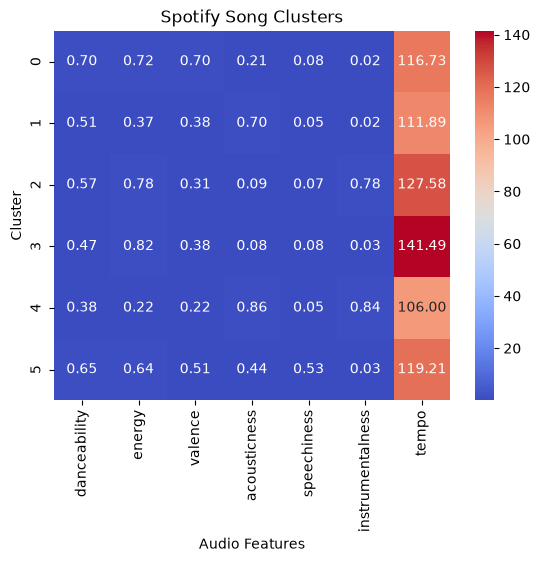

In [15]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.heatmap(
    cluster_profiles,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Spotify Song Clusters")
plt.xlabel("Audio Features")
plt.ylabel("Cluster")
plt.show()

In [17]:
for cluster in range(6):
    print(f"\nCluster {cluster}")
    print(sample[sample["cluster"] == cluster][
        ["track_name", "artists", "track_genre"]
    ].head(5))


Cluster 0
                   track_name       artists track_genre
91368         Merry Christmas   Bryan Adams        rock
61000                   月の大きさ    Nogizaka46      j-idol
96815  Jah Jah Revolta, Pt. 2  BaianaSystem       samba
25788  I'm Ready - Radio Edit          Kano       disco
62735                   時間がない       KIRINJI       j-pop

Cluster 1
                                               track_name  \
59311                               Save the Trees, Pt. 1   
19261   I'll Be Home For Christmas - From The Kacey Mu...   
108051                                                Sur   
115                               In Case You Didn’t Know   
87994                                     O Sopro do Fole   

                                                  artists track_genre  
59311                          Zhoobin Askarieh;Ali Sasha     iranian  
19261                        Kacey Musgraves;Lana Del Rey     country  
108051  Aníbal Troilo Y Su Orquesta Típica;Roberto Goy...  